> **Вариант 1 выключен** (`RUN_V1 = False` в `common/settings.py`): ноутбук остановится на проверке. Чтобы вернуть расчёт, поставить `True`.

> **Пересчёт.** Основа — `petri_states_results_all.ipynb` из папки `петри`; код расчёта тот же, пути и флаги — из `common/settings.py`. Папки: `out/long365_v1/`, `out/flags/`. Базовые контрольные точки теперь всегда в `align_ckpt/`, досчёт — в `align_ckpt_retry120s/`. Только чтение результатов. Текст с числами и выводами написан по **прежнему** расчёту: после пересчёта сверить (`common/compare_with_old.py`).

# Журнал состояний: все результаты — вся история (без окна)

Ноутбук собирает готовые результаты из `out_states\all\` и `out_states\flags\`.
Ничего не пересчитывает: после досчёта тайм-аутов достаточно выполнить его заново.

**Флаги журнала** во всех расчётах, кроме перебора флагов:
`SHORT_CUSTODY_DAYS` = 15, `LONG_CUSTODY_DAYS` = 365.

| Раздел | Что | Где посчитано |
|---|---|---|
| 1 | Все майнеры, сеть строится и проверяется на всём журнале | `petri_states.ipynb`, шаг 3 |
| 2 | Лучшие майнеры, люди train/test 80/20, alignments | `petri_states_eval_all.ipynb`, `run_split.py` |
| 3 | Досчёт тайм-аутов alignments с большим лимитом | `retry_timeouts.py` |
| 4 | Сводка по лучшим моделям | собирается здесь из 1–3 |
| 5 | Рисунки сетей лучших моделей и DFG | `petri_states.ipynb`, шаг 3 |
| 6 | Флаги `SHORT` / `LONG` | `petri_states_flags.ipynb` |
| 7 | Выводы | |

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "common"))
import settings as cfg

PART = "all"                         # "2013" — с окном, "all" — без окна

import json
import pandas as pd
from IPython.display import display, Image

EXP = PART
OUT = cfg.out_dir(PART, "long365_v1")
FLAGS = cfg.out_dir(PART, "flags")
BEST = ["flower", "DFG_p0.05", "HM_dep0.95", "SplitMiner", "IM_noise0.2"]
pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 40)


def read_jsonl(p):
    p = Path(p)
    if not p.exists():
        return pd.DataFrame()
    return pd.DataFrame([json.loads(l) for l in p.read_text(encoding="utf-8").splitlines() if l.strip()])


mq = pd.read_csv(OUT / "model_quality.csv")
se = read_jsonl(OUT / "split_eval.jsonl")
rt = pd.concat([read_jsonl(p) for p in sorted(OUT.glob("split_eval_retry*s.jsonl"))] or [pd.DataFrame()],
               ignore_index=True)
print("файлы:", OUT / "model_quality.csv", OUT / "split_eval.jsonl",
      *[p.name for p in sorted(OUT.glob("split_eval_retry*s.jsonl"))], sep="\n  ")

файлы:
  D:\diploma\jupyter lab\петри_пересчет\без_окна\out\long365_v1\model_quality.csv
  D:\diploma\jupyter lab\петри_пересчет\без_окна\out\long365_v1\split_eval.jsonl
  split_eval_retry120s.jsonl


In [2]:
assert cfg.RUN_V1, "Вариант 1 выключен: RUN_V1 = False в common/settings.py. Этот ноутбук запускать не нужно."

## 1. Все майнеры: сеть строится и проверяется на всём журнале

Без разбиения train/test и без alignments: насколько модель описывает данные, а не прогноз.

- `fitness_tbr` — fitness token-based replay; `pct_fit_traces_tbr` — % трасс, прошедших без ошибок;
- `precision_etc` — precision ETC (escaping edges);
- `precision_norm = (P − P_flower) / (1 − P_flower)`: 0 — не лучше цветочной сети, 1 — максимум;
- `f1 = 2·fitness·precision / (fitness + precision)`.

In [3]:
cols = ["model", "places", "transitions", "silent", "fitness_tbr", "pct_fit_traces_tbr",
        "precision_etc", "precision_flower", "precision_norm", "f1"]
mq[cols].sort_values("f1", ascending=False).set_index("model")

,places,transitions,silent,fitness_tbr,pct_fit_traces_tbr,precision_etc,precision_flower,precision_norm,f1
model,,,,,,,,,
DFG_p0.05,15,35,1,0.957,50.205,0.702,0.226,0.615,0.810
SplitMiner,20,40,27,0.726,0.009,0.887,0.226,0.854,0.798
IM_noise0.2,30,41,31,0.984,33.017,0.524,0.226,0.385,0.684
HM_dep0.95,16,43,31,0.984,0.000,0.417,0.226,0.246,0.585
HM_dep0.99,16,43,31,0.984,0.000,0.417,0.226,0.246,0.585
HM_dep0.9,16,44,32,0.984,0.000,0.412,0.226,0.240,0.581
IM_noise0.0,45,65,52,1.000,100.000,0.321,0.226,0.123,0.486
DFG_p0.0,15,84,1,1.000,100.000,0.302,0.226,0.098,0.464
POWL,38,50,37,1.000,100.000,0.226,0.226,0.000,0.369


## 2. Лучшие майнеры: train/test 80/20 и alignments

- люди делятся 80/20 (seed 42): сеть строится на train, метрики считаются на test;
- alignments — на **всём** test, лимит **20 с** на вариант трассы;
  варианты, не уложившиеся в лимит, в alignment fitness не входят (столбец `align_timeout`);
- перед alignments проверяется easy soundness: если финальная разметка недостижима, alignments не определены.

In [4]:
cols = [k for k in ["model", "places", "transitions", "silent", "train_traces", "test_traces",
                    "fitness_tbr_train", "fitness_tbr_test", "pct_fit_traces_tbr_test", "precision_etc_test",
                    "easy_sound", "fitness_align_test", "pct_fit_traces_align_test", "align_traces",
                    "align_timeout", "align_max_sec_trace", "note"] if k in se.columns]
se[cols].set_index("model")

,places,transitions,silent,train_traces,test_traces,fitness_tbr_train,fitness_tbr_test,pct_fit_traces_tbr_test,precision_etc_test,easy_sound,fitness_align_test,pct_fit_traces_align_test,align_traces,align_timeout,align_max_sec_trace
model,,,,,,,,,,,,,,,
flower,3,15,2,9178,2295,1.000,1.000,100.000,0.189,NaN,NaN,NaN,NaN,NaN,20
HM_dep0.95,16,43,31,9178,2295,0.984,0.984,0.000,0.358,False,NaN,NaN,2295.0,NaN,20
DFG_p0.05,15,35,1,9178,2295,0.956,0.957,49.281,0.620,True,0.919,48.235,2295.0,0.0,20
SplitMiner,25,41,28,9178,2295,0.720,0.720,0.000,0.884,True,0.114,0.000,2295.0,0.0,20
IM_noise0.2,30,41,31,9178,2295,0.984,0.984,32.462,0.453,True,0.937,32.590,2295.0,9.0,20


## 3. Попытка досчёта alignments с большим лимитом

**Как шёл расчёт:**
1. Alignments на всём test с лимитом **20 с** на вариант трассы (раздел 2); варианты, не уложившиеся в лимит, —
   тайм-ауты, в alignment fitness они не входят.
2. Тайм-ауты пересчитывались с лимитом **120 с** (`retry_timeouts.py`, папка `align_ckpt_20s` → `align_ckpt_retry120s`);
   готовые варианты не пересчитывались, порядок моделей: DFG p0.05 → Split Miner → IM 0.2.
3. **Досчёт остановлен 04.11.2026 в 20:42** — ресурсы отданы пересчёту журнала версии 2
   (`petri_states_v2_results_{2013,all}.ipynb`). Контрольные точки сохранены: при запуске `retry_timeouts.py`
   досчёт продолжится с места.

Таблица ниже собирается по контрольным точкам:
- `тайм-аутов при лимите` — трасс test, не уложившихся в исходный лимит;
- `перепроверено вариантов` / `выровнено трасс` — сколько из них пересчитано с большим лимитом и сколько выровнялось;
- `не досчитано трасс`, `доля test` — сколько трасс так и не вошло в alignment fitness;
- `alignment fitness сейчас` — с учётом всего, что досчитано (в том числе для моделей, досчёт которых не закончен).

HM 0.95 на всей истории — не тайм-ауты: сеть не easy sound, alignments для неё не определены.

In [5]:
BASE = OUT / "align_ckpt"
RETRY = OUT / "align_ckpt_retry120s"
rows = []
for m in BEST[1:]:
    b = read_jsonl(BASE / f"{m}_align.jsonl")
    if b.empty:
        continue
    r = read_jsonl(RETRY / f"{m}_align.jsonl")
    to = b[b.timeout]
    rr = r.set_index("i") if not r.empty else pd.DataFrame(columns=["timeout", "n"])
    ok_retry = rr[~rr.timeout.astype(bool)] if len(rr) else rr
    allr = pd.concat([b[~b.timeout].set_index("i"), ok_retry])
    sound = se.set_index("model").get("easy_sound", pd.Series(dtype=object)).get(m)
    fit = None if allr.empty or sound is False else 1 - (allr.cost * allr.n).sum() / (allr.bwc * allr.n).sum()
    not_done = int(to.n.sum() - ok_retry.n.sum()) if len(rr) else int(to.n.sum())
    rows.append({"модель": m, "трасс test": int(b.n.sum()),
                 "тайм-аутов при лимите": int(to.n.sum()), "вариантов с тайм-аутом": len(to),
                 "перепроверено вариантов": len(rr), "выровнено трасс": int(ok_retry.n.sum()) if len(rr) else 0,
                 "не досчитано трасс": not_done, "доля test, %": round(100 * not_done / b.n.sum(), 1),
                 "alignment fitness сейчас": fit,
                 "примечание": "не easy sound — alignments не определены" if sound is False else "тайм-аутов нет" if to.empty else
                               ("досчёт закончен" if m in set(rt.get("model", [])) else
                                ("досчёт остановлен" if len(rr) else "досчёт не начинался"))})
pd.DataFrame(rows).set_index("модель").round(3)

,трасс test,тайм-аутов при лимите,вариантов с тайм-аутом,перепроверено вариантов,выровнено трасс,не досчитано трасс,"доля test, %",alignment fitness сейчас,примечание
модель,,,,,,,,,
DFG_p0.05,2295,0,0,0,0,0,0.0,0.919,тайм-аутов нет
SplitMiner,2295,0,0,0,0,0,0.0,0.114,тайм-аутов нет
IM_noise0.2,2295,9,9,9,9,0,0.0,0.937,досчёт закончен


In [6]:
# модели, для которых досчёт закончен: итог (лимит, сколько тайм-аутов было и осталось)
if not rt.empty:
    display(rt[["model", "retry_of", "align_max_sec_trace", "align_timeout_before", "align_timeout",
                "align_traces", "fitness_align_test", "pct_fit_traces_align_test", "finished"]].set_index("model"))

,retry_of,align_max_sec_trace,align_timeout_before,align_timeout,align_traces,fitness_align_test,pct_fit_traces_align_test,finished
model,,,,,,,,
IM_noise0.2,20,120,9,0,2295,0.937,32.462,2026-11-06 02:29


## 4. Сводка по лучшим моделям

Весь журнал (раздел 1) + test (раздел 2) + итоговые alignments: если для модели есть досчёт
с большим лимитом (раздел 3), берётся он. Precision нормируется на цветочную сеть **на test**.

In [7]:
P_FLOWER = se.loc[se.model == "flower", "precision_etc_test"].iloc[0]
rows = []
for m in BEST:
    q = mq.set_index("model").loc[m] if m in set(mq.model) else None
    s = se.set_index("model").loc[m]
    r = rt[rt.model == m].sort_values("align_max_sec_trace").iloc[-1] if (not rt.empty and m in set(rt.model)) else None
    a = r if r is not None else s
    fa = a.get("fitness_align_test")
    p = s["precision_etc_test"]
    rows.append({
        "модель": m,
        "F1 весь журнал": None if q is None else q["f1"],
        "fitness TBR train": s["fitness_tbr_train"],
        "fitness TBR test": s["fitness_tbr_test"],
        "precision test": p,
        "precision норм. test": None if m == "flower" else (p - P_FLOWER) / (1 - P_FLOWER),
        "F1 TBR test": None if m == "flower" else 2 * s["fitness_tbr_test"] * p / (s["fitness_tbr_test"] + p),
        "easy sound": s.get("easy_sound"),
        "alignment fitness test": None if m == "flower" else fa,
        "F1 alignments test": None if (m == "flower" or pd.isna(fa)) else 2 * fa * p / (fa + p),
        "лимит, с": None if m == "flower" else a.get("align_max_sec_trace"),
        "доля тайм-аутов": None if (m == "flower" or pd.isna(a.get("align_timeout"))) else a["align_timeout"] / s["test_traces"],
    })
summary = pd.DataFrame(rows).set_index("модель")
summary["доля тайм-аутов"] = (summary["доля тайм-аутов"] * 100).round(1)
summary = summary.rename(columns={"доля тайм-аутов": "тайм-аутов, %"})
summary.round(3)

,F1 весь журнал,fitness TBR train,fitness TBR test,precision test,precision норм. test,F1 TBR test,easy sound,alignment fitness test,F1 alignments test,"лимит, с","тайм-аутов, %"
модель,,,,,,,,,,,
flower,0.369,1.000,1.000,0.189,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DFG_p0.05,0.810,0.956,0.957,0.620,0.531,0.752,True,0.919,0.740,20.0,0.0
HM_dep0.95,0.585,0.984,0.984,0.358,0.209,0.525,False,NaN,NaN,20.0,NaN
SplitMiner,0.798,0.720,0.720,0.884,0.857,0.793,True,0.114,0.202,20.0,0.0
IM_noise0.2,0.684,0.984,0.984,0.453,0.326,0.621,True,0.937,0.611,120.0,0.0


## 5. Сети лучших моделей и DFG

Сети построены на всём журнале (раздел 1). DFG — все пары соседних состояний с частотами, без фильтра.

DFG_p0.05


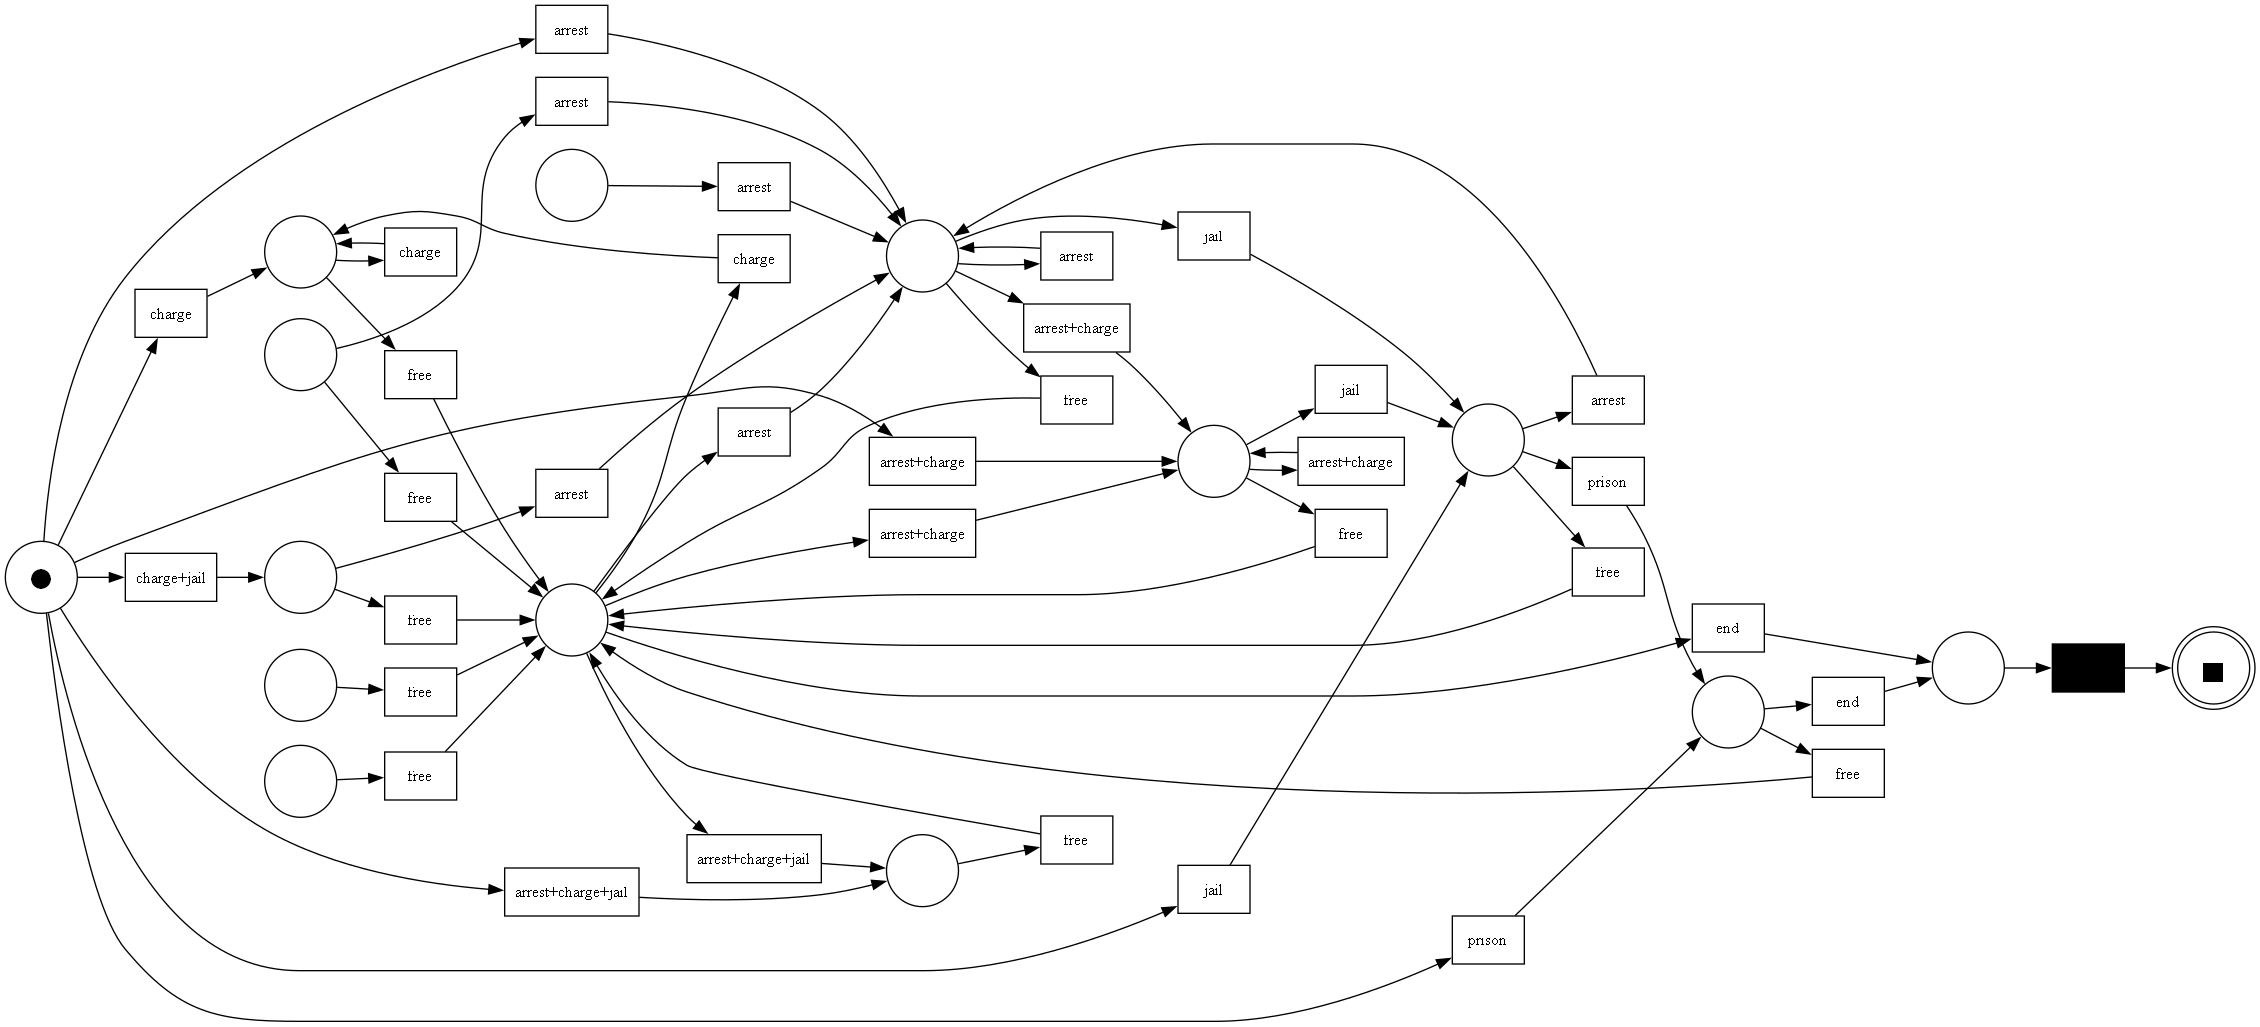

HM_dep0.95


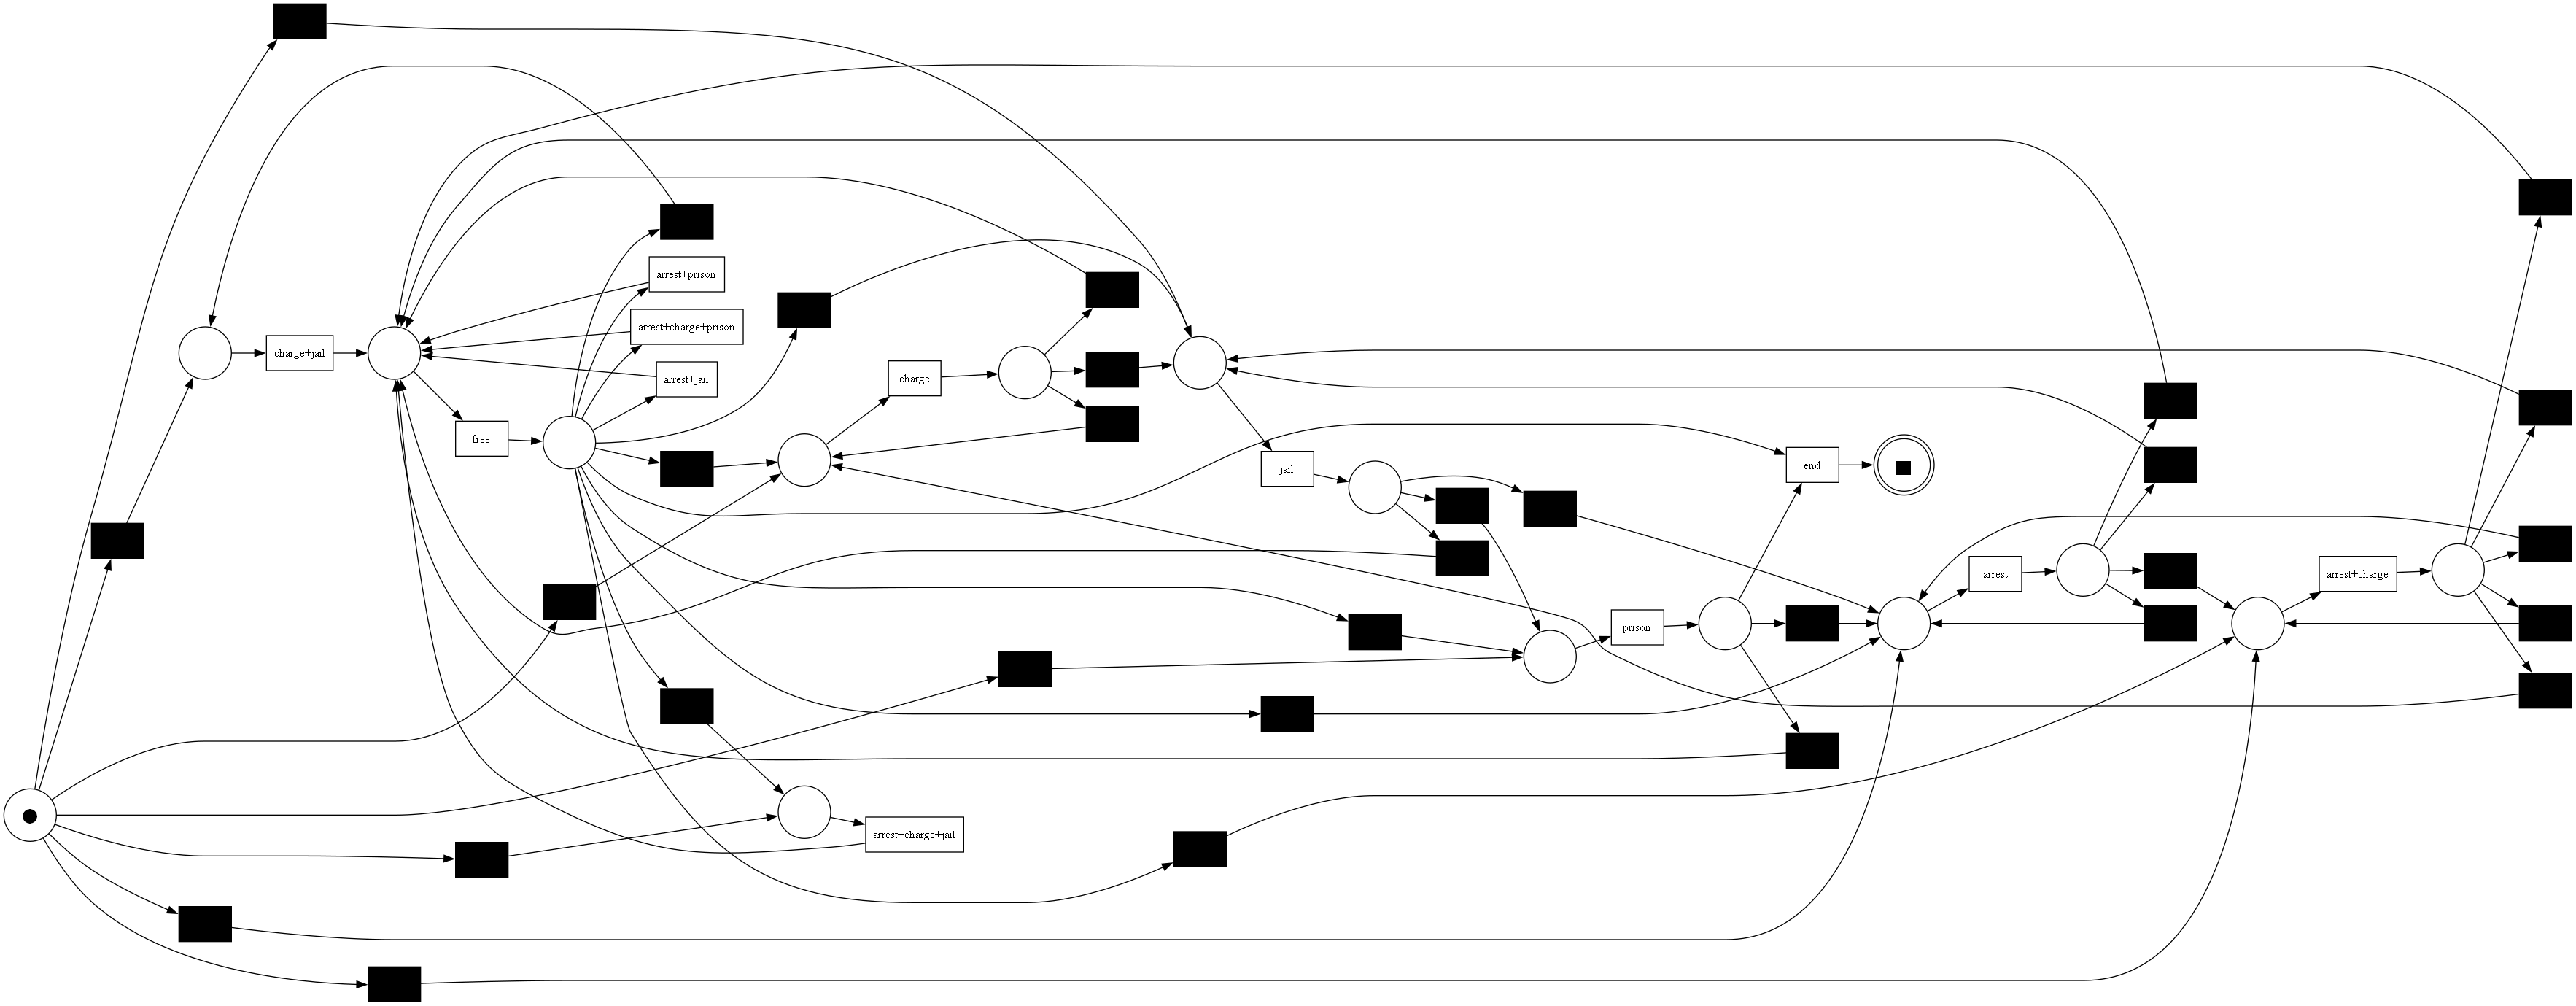

SplitMiner


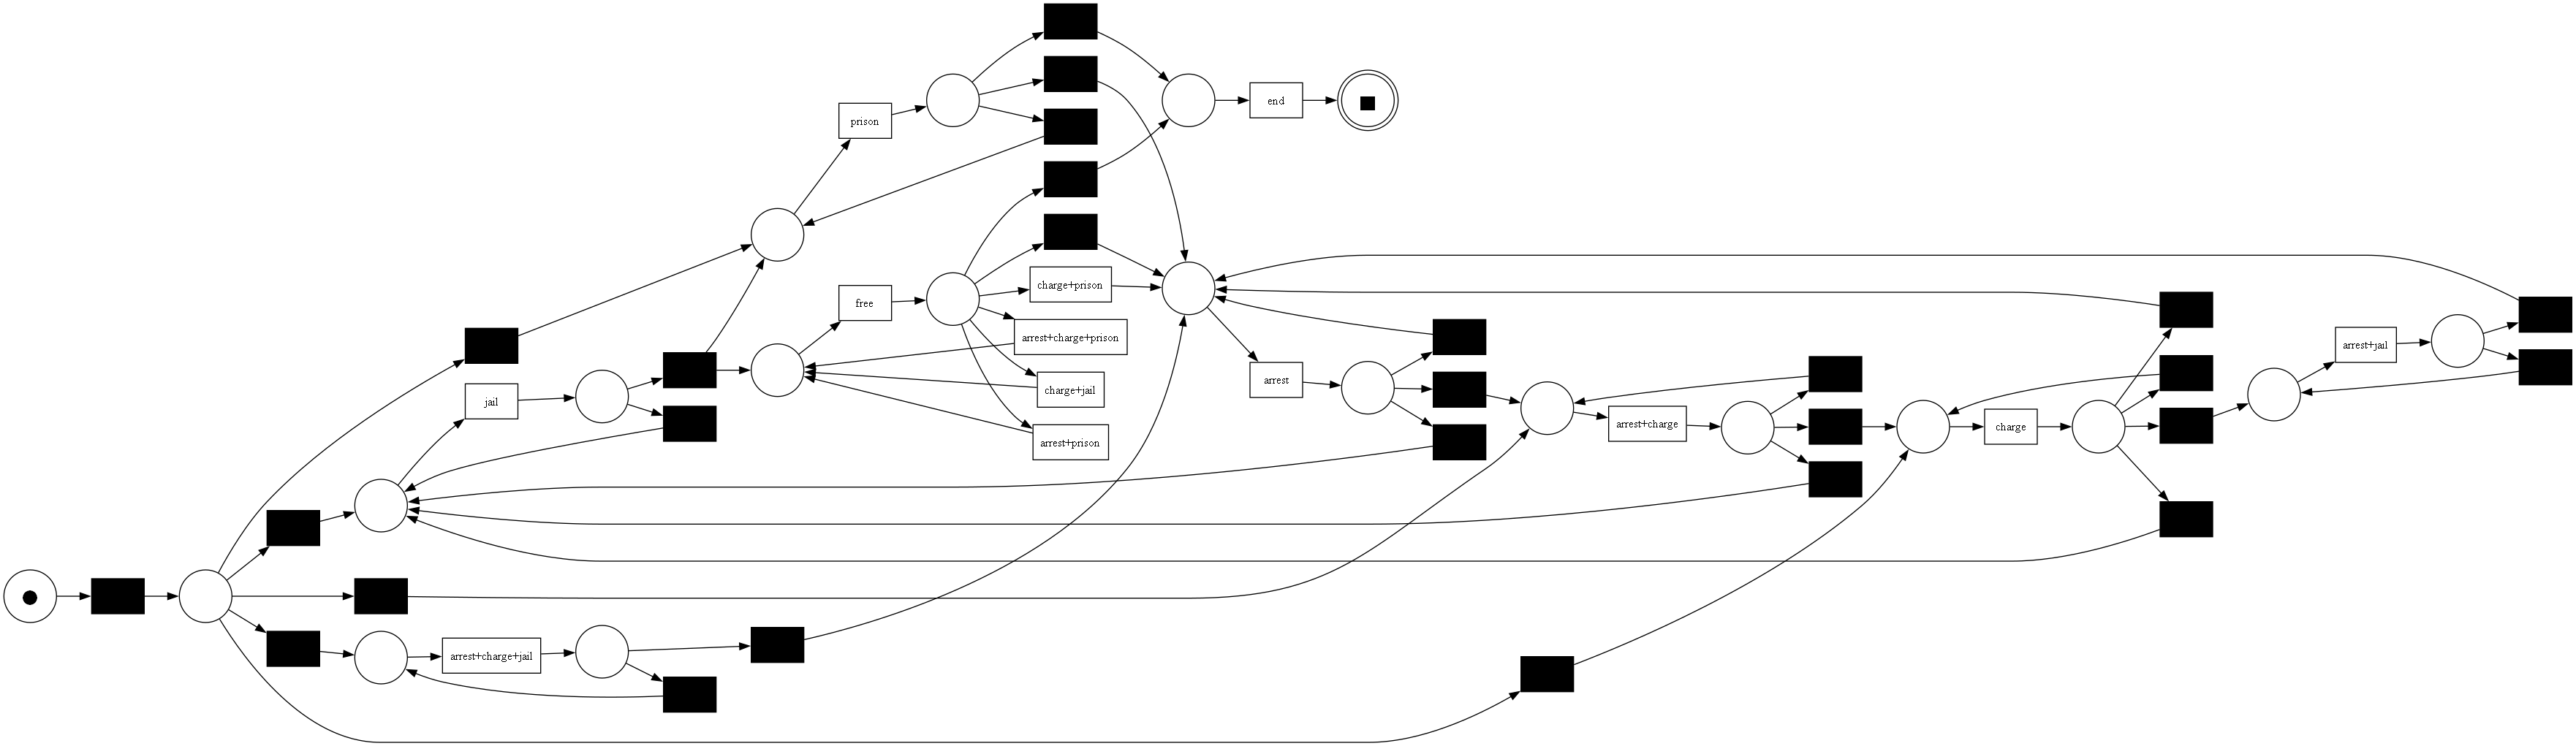

IM_noise0.2


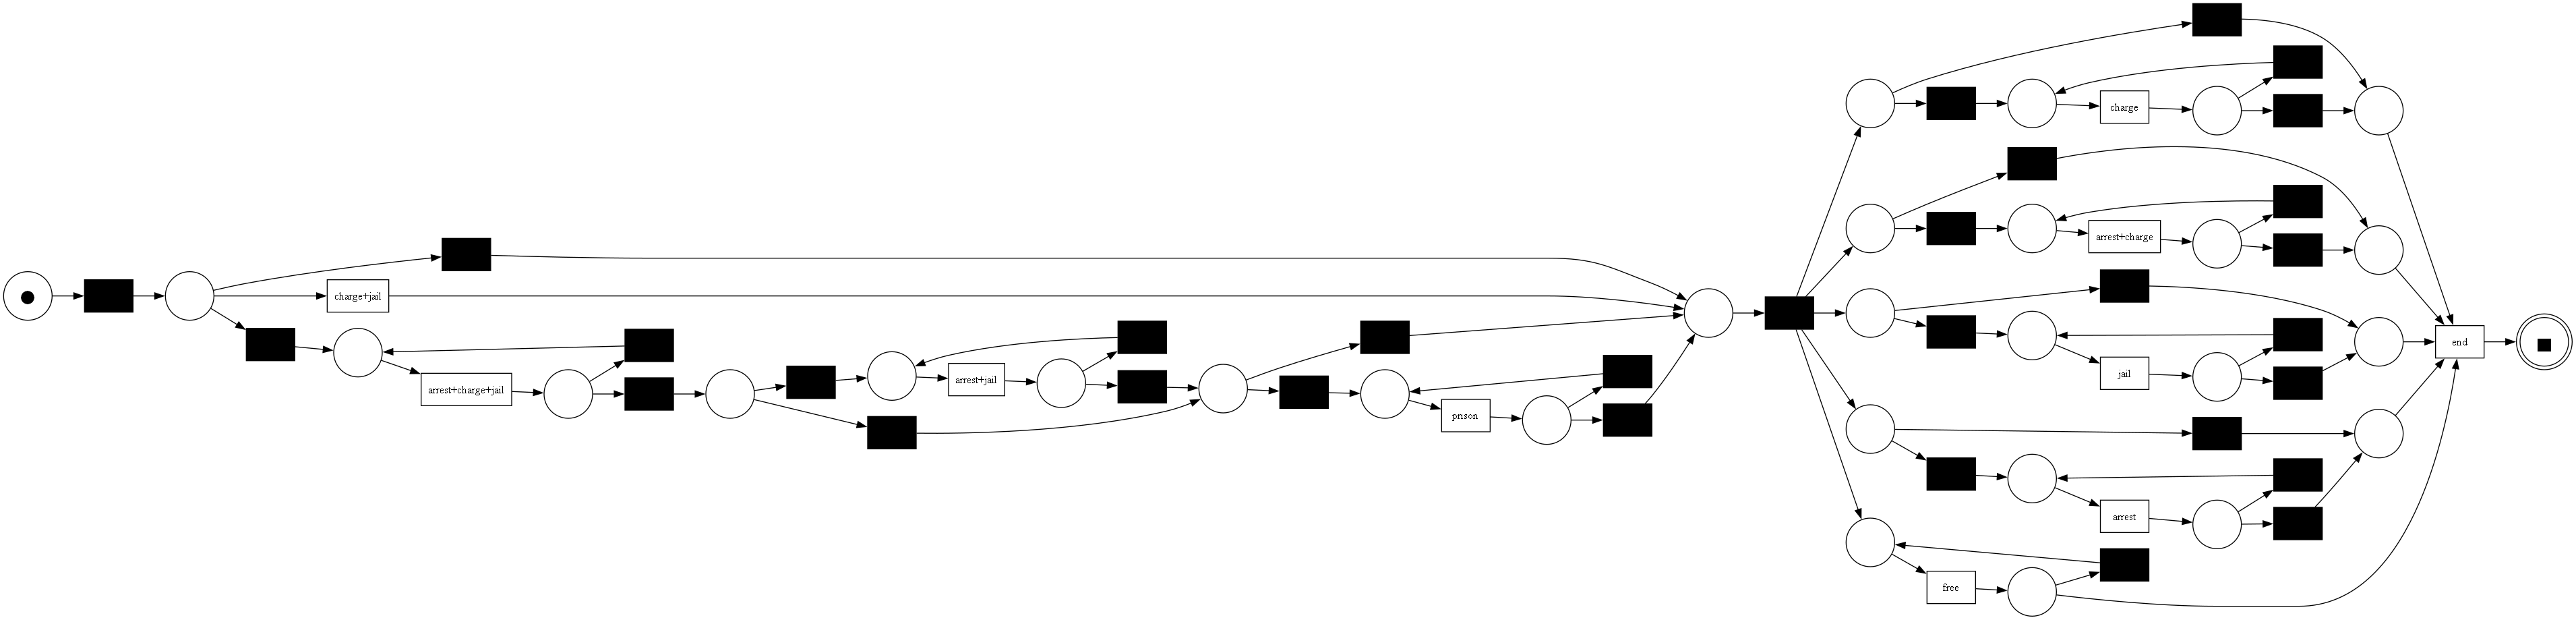

DFG, частоты


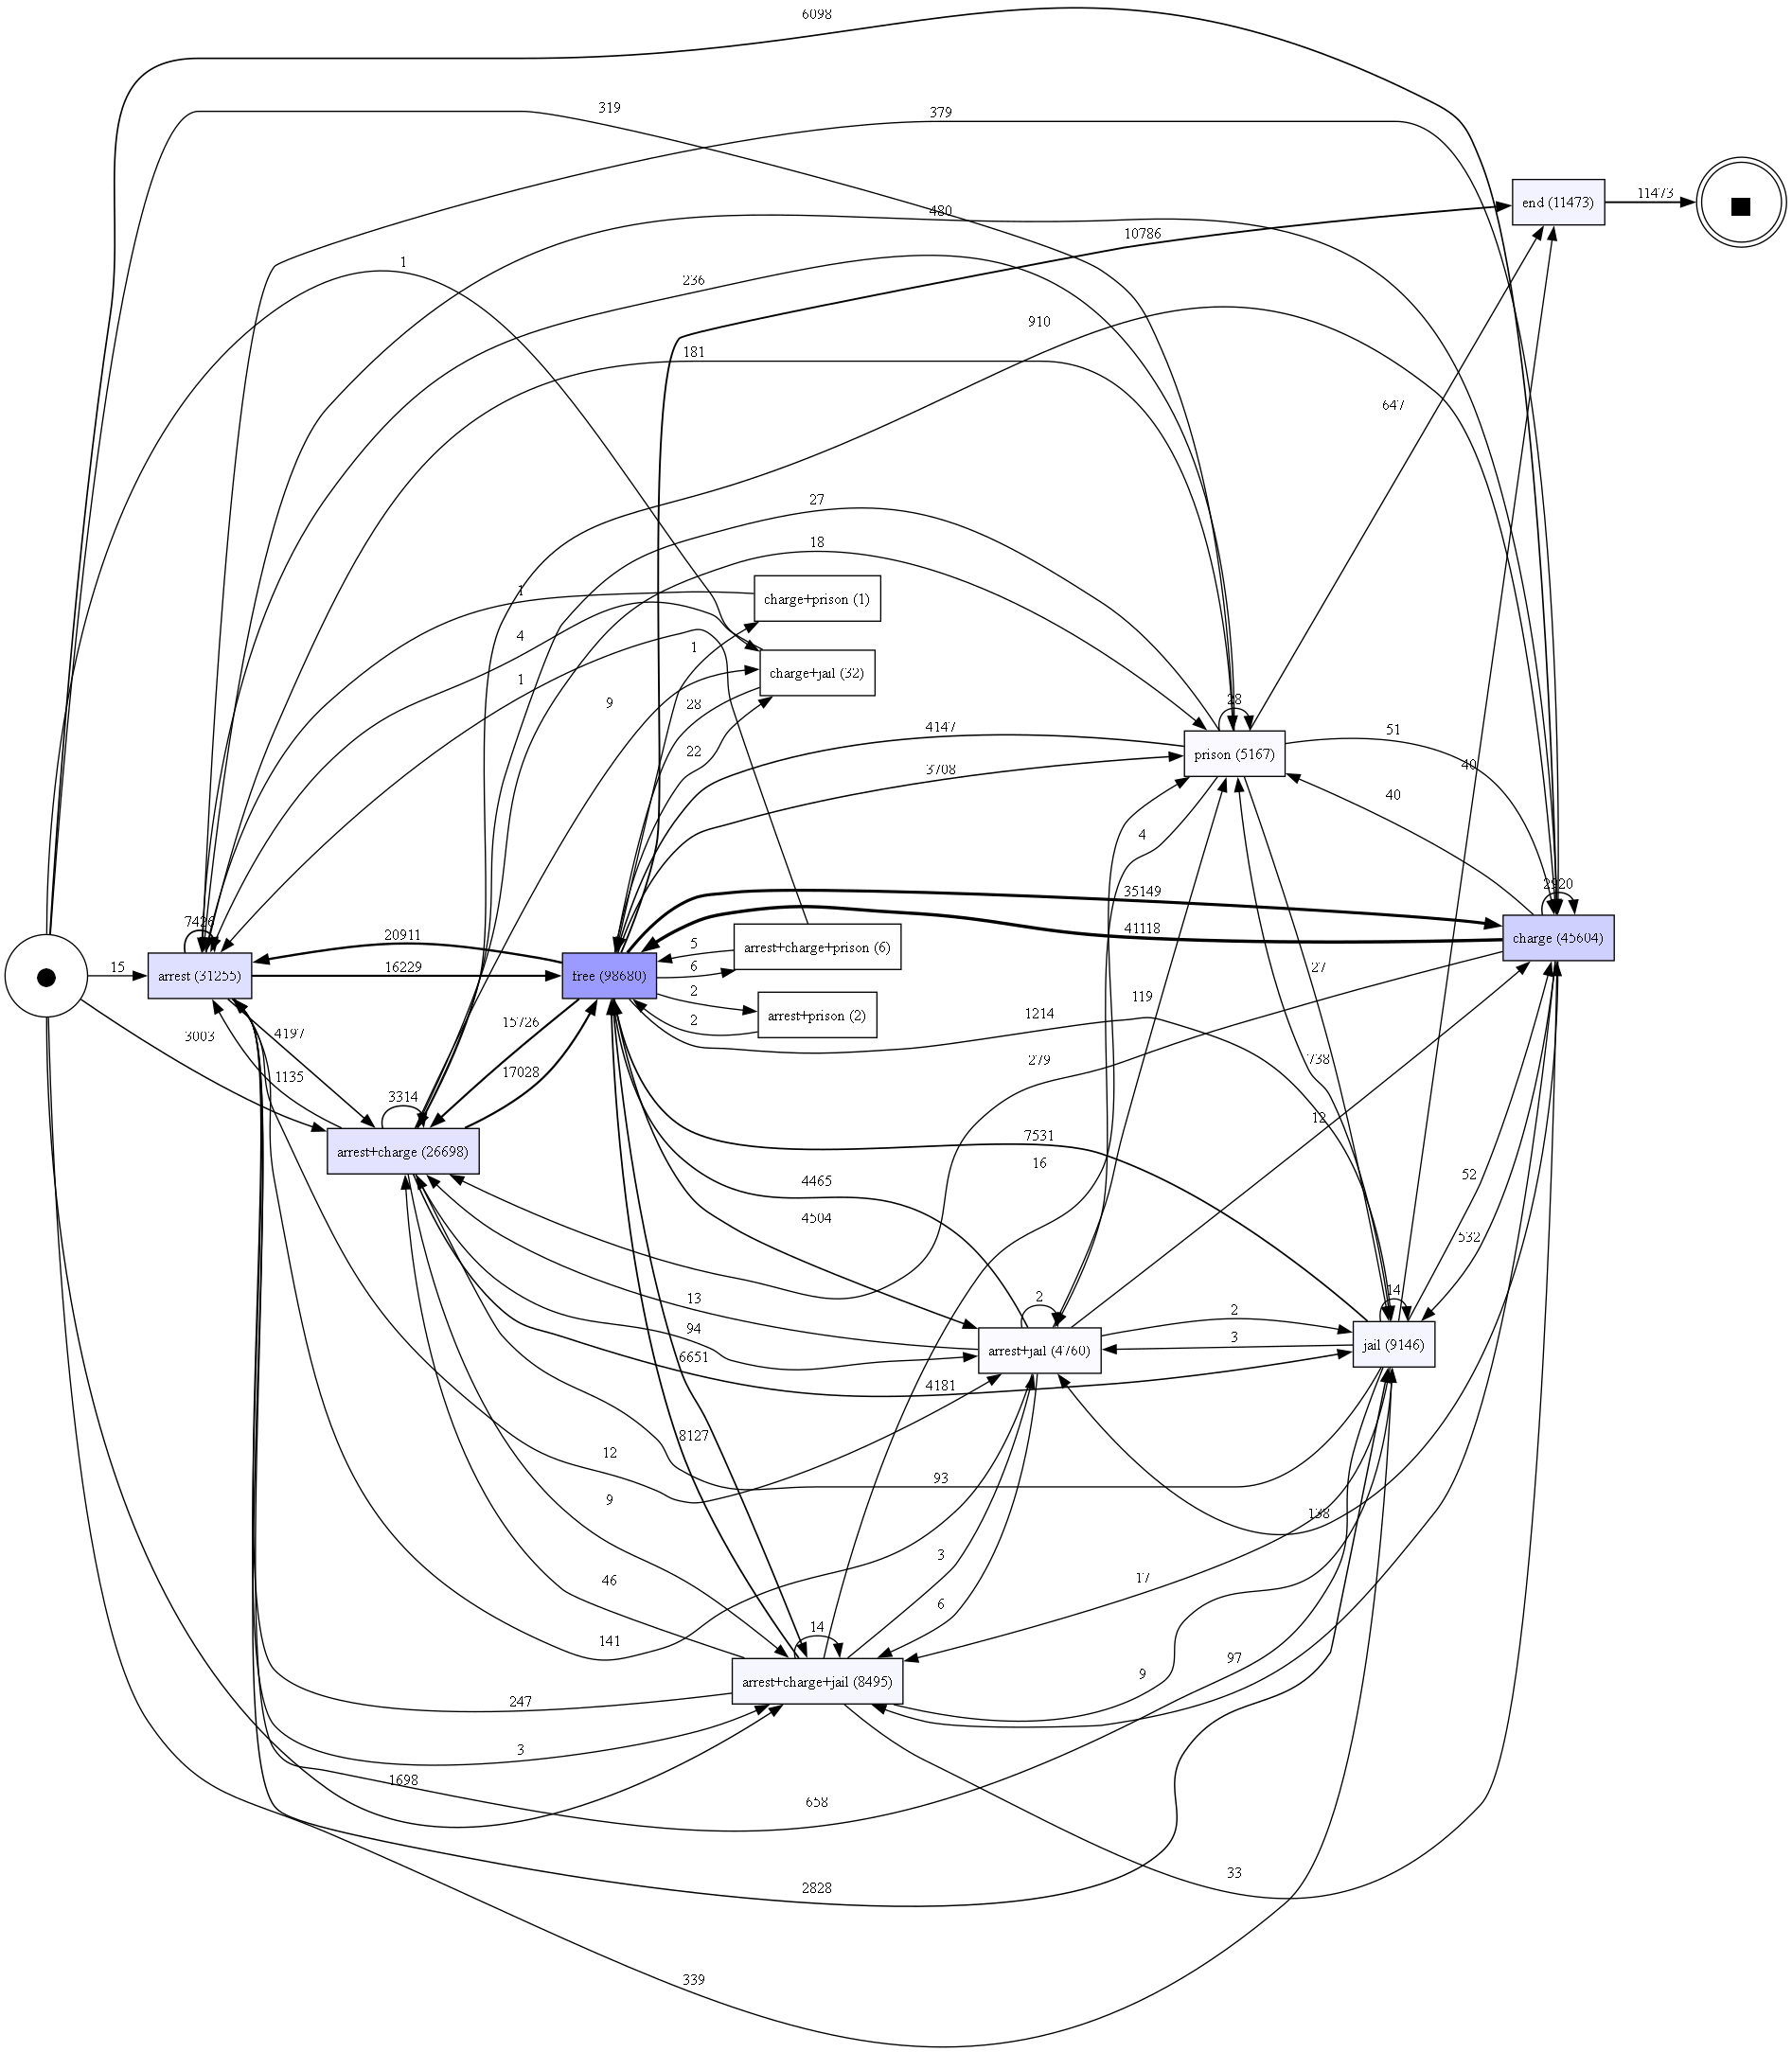

In [8]:
for m in BEST[1:]:
    p = OUT / f"net_{m}.png"
    if p.exists():
        print(m)
        display(Image(filename=str(p), width=1000))
p = OUT / "dfg_frequency.png"
if p.exists():
    print("DFG, частоты")
    display(Image(filename=str(p), width=1000))

## 6. Флаги `SHORT_CUSTODY_DAYS` и `LONG_CUSTODY_DAYS`

Перебор флагов (`petri_states_flags.ipynb`, шаг 5): сеть на train, на test — TBR fitness и ETC precision,
без alignments; `long = 100000` — правило 5 выключено. Модели: DFG p0.05, HM 0.95, Split Miner.

In [9]:
sw = pd.read_csv(FLAGS / "flags_sweep_table.csv")
sw = sw[sw["exp"].astype(str) == "all"].drop(columns="exp").sort_values(["seed", "short", "long"])
sw.set_index(["seed", "short", "long"])

F1 DFG_p0.05  F1 HM_dep0.95  F1 SplitMiner  F1 среднее  \
seed short long                                                           
42   5     180          0.753          0.525          0.785       0.688   
     15    180          0.753          0.525          0.798       0.692   
           365          0.752          0.525          0.793       0.690   

                 Pnorm DFG_p0.05  Pnorm HM_dep0.95  Pnorm SplitMiner  \
seed short long                                                        
42   5     180             0.522             0.194             0.762   
     15    180             0.522             0.193             0.845   
           365             0.531             0.209             0.857   

                 variants_test  composite  absorbed  inside  
seed short long                                              
42   5     180            1631      12806        76    1714  
     15    180            1630      12806       181    1609  
           365            1626      13228       181    1609

Длительность эпизодов заключения по зонам правил (вся база), дни: при текущих флагах (15 / 365)
и рекомендованных (15 / 180).

In [10]:
display(pd.read_csv(FLAGS / "domain_medians_current.csv").set_index(pd.read_csv(FLAGS / "domain_medians_current.csv").columns[0]))
display(pd.read_csv(FLAGS / "domain_medians_recommended.csv").set_index(pd.read_csv(FLAGS / "domain_medians_recommended.csv").columns[0]))

,n,q25,median,q75,доля prison
"зона (SHORT=15, LONG=365)",,,,,
все эпизоды,25231,1.06,7.31,81.96,0.19
"3: одно дело в день входа, < LONG (составное)",13230,0.97,2.02,19.36,0.01
4: несколько дел в день входа,4387,1.20,12.60,64.95,0.08
"5: одно дело в день входа, ≥ LONG (дело → заключение)",327,470.01,609.56,827.99,0.87
без дела в день входа,7287,4.83,117.76,433.00,0.57
"6: события внутри срока, < SHORT (склейка)",154,2.94,6.04,9.52,0.01
"7: события внутри срока, ≥ SHORT (jail → дело → jail)",1141,54.01,156.62,479.00,0.34


,n,q25,median,q75,доля prison
"зона (SHORT=15, LONG=180)",,,,,
все эпизоды,25231,1.06,7.31,81.96,0.19
"3: одно дело в день входа, < LONG (составное)",12808,0.95,1.93,15.16,0.00
4: несколько дел в день входа,4387,1.20,12.60,64.95,0.08
"5: одно дело в день входа, ≥ LONG (дело → заключение)",749,240.12,330.93,564.48,0.53
без дела в день входа,7287,4.83,117.76,433.00,0.57
"6: события внутри срока, < SHORT (склейка)",154,2.94,6.04,9.52,0.01
"7: события внутри срока, ≥ SHORT (jail → дело → jail)",1141,54.01,156.62,479.00,0.34


Профиль по длительности эпизода (вся база):
- **LONG** — доля эпизодов с prison и с делом в день входа: где задержание по делу становится «сроком»;
- **SHORT** — события внутри срока: доля на следующий день после входа и медиана дней от входа.

In [11]:
display(pd.read_csv(FLAGS / "long_profile.csv").set_index("dur"))
display(pd.read_csv(FLAGS / "short_profile.csv").set_index("dur"))

,эпизодов,доля_prison,доля_с_делом_в_день_входа,доля_одно_дело
dur,,,,
"[0.0, 30.0)",15767,0.010,0.836,0.669
"[30.0, 60.0)",2294,0.058,0.797,0.537
"[60.0, 90.0)",1088,0.188,0.698,0.437
"[90.0, 120.0)",747,0.299,0.600,0.380
"[120.0, 150.0)",476,0.443,0.515,0.298
"[150.0, 180.0)",405,0.405,0.533,0.309
"[180.0, 210.0)",350,0.520,0.466,0.291
"[210.0, 240.0)",336,0.625,0.411,0.247
"[240.0, 270.0)",358,0.564,0.453,0.274


,единиц,доля_на_след_день,медиана_дней_от_входа,доля_то_же_дело
dur,,,,
"[0.0, 3.0)",51,0.941,1.0,0.118
"[3.0, 7.0)",59,0.644,1.0,0.119
"[7.0, 10.0)",30,0.733,1.0,0.067
"[10.0, 15.0)",41,0.561,1.0,0.244
"[15.0, 20.0)",37,0.432,3.0,0.189
"[20.0, 30.0)",66,0.424,3.0,0.136
"[30.0, 45.0)",168,0.327,9.0,0.167
"[45.0, 60.0)",97,0.258,12.0,0.206
"[60.0, 90.0)",145,0.290,11.0,0.166


## 7. Выводы (вся история) — промежуточные

*Досчёт тайм-аутов с лимитом 120 с остановлен 04.11 (раздел 3): числа alignments ниже — с лимитом 20 с;
без учёта остаются 13% трасс test у DFG p0.05, 19% у Split Miner и 36% у IM 0.2.*

**DFG p0.05** — по-прежнему лучший баланс:
- alignment fitness 0.936 (без 13% трасс с тайм-аутом), precision ETC 0.620, нормированная 0.531;
- TBR fitness на train и test совпадает (0.957 / 0.958) — переобучения нет.

**Split Miner** — самая высокая precision (0.884, нормированная 0.857), но сеть почти не воспроизводит
трассы: TBR fitness 0.720, alignment fitness 0.154. Выровненные трассы проходят сеть только
по тихим переходам — видимая часть сети почти не доходит до конца. Для alignments сеть непригодна.

**HM 0.95** — сеть не easy sound (финальная разметка недостижима): alignments не определены;
TBR fitness 0.984, но precision 0.358 (нормированная 0.209).

**IM 0.2** — alignment fitness 0.959 (с частично досчитанными тайм-аутами — 0.956), precision 0.453 (нормированная 0.326);
тайм-аутов 39% (после частичного досчёта — 36%) — на alignment fitness опираться нельзя.

**Вся история сложнее окна 2013:** precision цветочной сети 0.189 против 0.358 —
состояний больше и они разнообразнее, поэтому все модели здесь слабее.

## Таблица Excel

Прежний `make_results_tables.py`: итоговый файл появится в папке этой части.

In [12]:
import align_parallel as ap
ap.launch([cfg.COMMON / "make_results_tables.py", PART])

D:\Git\diploma\.venv\Scripts\python.exe -u D:\diploma\jupyter lab\петри_пересчет\common\make_results_tables.py all


сохранено D:\diploma\jupyter lab\петри_пересчет\без_окна\results_states_all.xlsx
